In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, Lasso
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')

In [3]:
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [4]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Frame Index              10332 non-null  int64  
 1   FPS                      10332 non-null  float64
 2   Frame Duration (ms)      10332 non-null  float64
 3   Min Frame Duration (ms)  10332 non-null  float64
 4   Max Frame Duration (ms)  10332 non-null  float64
 5   Avg Frame Duration (ms)  10332 non-null  float64
 6   Std Dev (ms)             10332 non-null  float64
 7   Entropy Framerate        10332 non-null  float64
 8   MotionToPhotonLatency    10332 non-null  float64
 9   minMtpLatency            10332 non-null  float64
 10  maxMtpLatency            10332 non-null  float64
 11  avgMtpLatency            10332 non-null  float64
 12  StdDev mtpLatency        10332 non-null  float64
 13  mtpEntropy               10332 non-null  float64
 14  currentRotation.x     

In [5]:
Data = Data.iloc[:, 1:]
#Data = Data.iloc[:, 0:]
#Data = Data.iloc[:, 1:-14]
#Data = Data.iloc[:, 8:-1]

In [6]:
Data 

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [7]:
Data['Labels'] = Data['FPS'].apply(lambda x: 0 if x>=60 else 1)
#Data["Labels"] = Data["MotionToPhotonLatency"].apply(lambda x: 0 if x <= 20 else 1)

In [8]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,...,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,...,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71,0
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,...,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73,0
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,...,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75,0
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,...,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85,0
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,...,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,...,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87,1
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,...,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15,1
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,...,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37,1
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,...,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80,1


In [9]:
Data.shape

(10332, 21)

In [10]:
X = Data.drop('Labels', axis = 1)

In [11]:
y = Data['Labels']

In [12]:
feature_names = X.columns

In [13]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled , y, test_size=0.3, random_state=42)

In [15]:
# Using LassoCV for cross-validated LASSO
model_cv = LassoCV(alphas=np.logspace(-5, 1, 100), cv=5)
model_cv.fit(X_train, y_train)
best_alpha_cv = model_cv.alpha_
print(f"Best alpha using LassoCV: {best_alpha_cv:.6f}")

Best alpha using LassoCV: 0.000433


In [16]:
# Using GridSearchCV for grid search
lasso = Lasso()
grid = {'alpha': np.logspace(-5, 1, 100)}
model_gs = GridSearchCV(lasso, grid, scoring='neg_mean_squared_error', cv=5)
model_gs.fit(X_train, y_train)
best_alpha_gs = model_gs.best_params_['alpha']
print(f"Best alpha using GridSearchCV: {best_alpha_gs:.6f}")

Best alpha using GridSearchCV: 0.000433


In [17]:
# Create the LASSO Regression model with an alpha value (regularization strength)
model = Lasso(alpha=0.000433, random_state=42)

In [18]:
# Fit the model to the training data
model.fit(X_train, y_train)

Lasso(alpha=0.000433, random_state=42)

In [19]:
# Predict on the test set
y_pred = model.predict(X_test)

In [20]:
# Evaluate the model using mean squared error (MSE)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean squared error: {mse:.4f}")

Mean squared error: 0.0335


In [21]:
# Get the coefficients of the LASSO model
coefficients = model.coef_

In [22]:
# Display the coefficients and corresponding feature names
lasso_coefficients = pd.DataFrame(coefficients, index=feature_names, columns=["Coefficients"])

In [23]:
lasso_coefficients

,Coefficients
FPS,-0.421131
Frame Duration (ms),-0.070948
Min Frame Duration (ms),-0.012179
Max Frame Duration (ms),0.000000
Avg Frame Duration (ms),-0.112819
Std Dev (ms),0.001587
Entropy Framerate,0.016161
MotionToPhotonLatency,-0.000000
minMtpLatency,-0.027041
maxMtpLatency,0.022685


In [24]:
# Reset index to convert feature names to a column
lasso_coefficients.reset_index(inplace=True)
lasso_coefficients.rename(columns={'index': 'Feature'}, inplace=True)

In [25]:
# Sort the DataFrame by coefficient values (from highest to lowest)
lasso_coefficients.sort_values(by='Coefficients', ascending=False, inplace=True)

In [26]:
# Print the sorted DataFrame
print("Sorted LASSO coefficients:")
print(lasso_coefficients)

Sorted LASSO coefficients:
                    Feature  Coefficients
10            avgMtpLatency      0.147429
9             maxMtpLatency      0.022685
6         Entropy Framerate      0.016161
18                      yaw      0.010530
13        currentRotation.x      0.006839
11        StdDev mtpLatency      0.004390
19                     roll      0.002504
5              Std Dev (ms)      0.001587
7     MotionToPhotonLatency     -0.000000
3   Max Frame Duration (ms)      0.000000
16        currentRotation.w     -0.000856
17                    pitch     -0.003053
12               mtpEntropy     -0.004481
2   Min Frame Duration (ms)     -0.012179
15        currentRotation.z     -0.025257
8             minMtpLatency     -0.027041
14        currentRotation.y     -0.041301
1       Frame Duration (ms)     -0.070948
4   Avg Frame Duration (ms)     -0.112819
0                       FPS     -0.421131


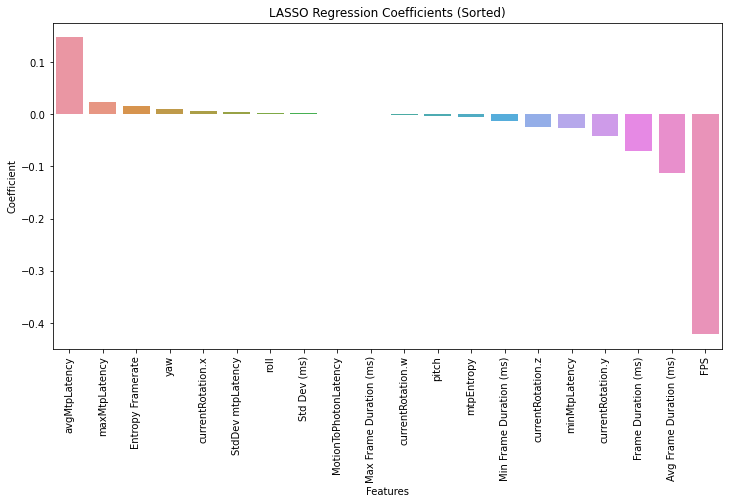

In [27]:
# Plot the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='Feature', y='Coefficients', data=lasso_coefficients)
plt.xticks(rotation=90)
plt.title("LASSO Regression Coefficients (Sorted)")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.show()

In [28]:
# Identify selected features based on non-zero coefficients
selected_features = feature_names[np.nonzero(coefficients)]
print("\nSelected features:")
print(selected_features)


Selected features:
Index(['FPS', 'Frame Duration (ms)', 'Min Frame Duration (ms)',
       'Avg Frame Duration (ms)', 'Std Dev (ms)', 'Entropy Framerate',
       'minMtpLatency', 'maxMtpLatency', 'avgMtpLatency', 'StdDev mtpLatency',
       'mtpEntropy', 'currentRotation.x', 'currentRotation.y',
       'currentRotation.z', 'currentRotation.w', 'pitch', 'yaw', 'roll'],
      dtype='object')


In [29]:
# Extract the non-zero coefficients
non_zero_coefficients = coefficients[np.nonzero(coefficients)]

In [30]:
# Create a DataFrame with the non-zero coefficients and corresponding feature names
lasso_nonzerocoef = pd.DataFrame({"Feature": selected_features, "Coefficient": non_zero_coefficients})

In [31]:
lasso_nonzerocoef

,Feature,Coefficient
0,FPS,-0.421131
1,Frame Duration (ms),-0.070948
2,Min Frame Duration (ms),-0.012179
3,Avg Frame Duration (ms),-0.112819
4,Std Dev (ms),0.001587
5,Entropy Framerate,0.016161
6,minMtpLatency,-0.027041
7,maxMtpLatency,0.022685
8,avgMtpLatency,0.147429
9,StdDev mtpLatency,0.004390


In [32]:
lasso_nonzerocoef.sort_values(by='Coefficient', ascending=False, inplace=True)

In [33]:
lasso_nonzerocoef

,Feature,Coefficient
8,avgMtpLatency,0.147429
7,maxMtpLatency,0.022685
5,Entropy Framerate,0.016161
16,yaw,0.010530
11,currentRotation.x,0.006839
9,StdDev mtpLatency,0.004390
17,roll,0.002504
4,Std Dev (ms),0.001587
14,currentRotation.w,-0.000856
15,pitch,-0.003053


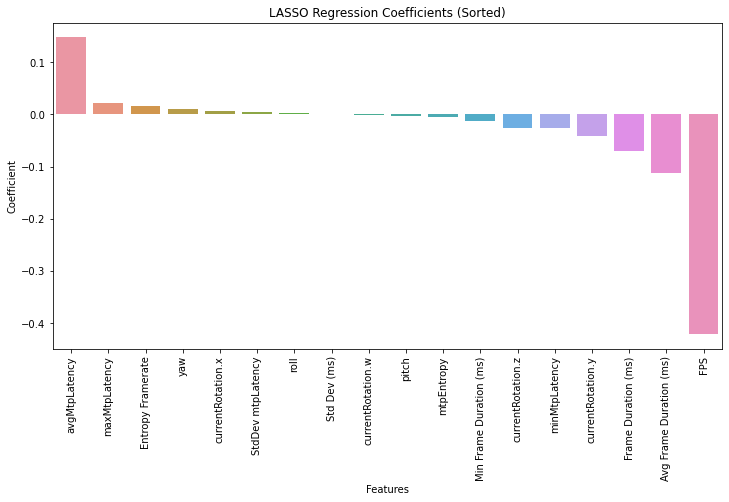

In [34]:
# Plot the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='Feature', y='Coefficient', data=lasso_nonzerocoef)
plt.xticks(rotation=90)
plt.title("LASSO Regression Coefficients (Sorted)")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.show()